# Fase 0: Configuración inicial

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as msno

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RUTA_DATASET = "data/raw/global_air_quality_data_messy.csv"

decisiones = []   # lista de dicts
def registrar(fase, columna, accion, justificacion):
    decisiones.append({"fase": fase, "columna": columna,
                       "accion": accion, "justificacion": justificacion})

# Fase I: Ingesta y perfilado inicial

## Carga de dataset y copia inmutable

In [5]:
df = pd.read_csv(RUTA_DATASET)
df_raw = df.copy(deep=True)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 30,450 | Columnas: 12


,City,Country,Date,PM2.5,PM10,NO2,SO2,CO,O3,Temperature,Humidity,Wind Speed
0,Johannesburg,South Africa,4/10/2023,127.51,175.10,NaN,13.02,1.70,196.41,27.46,51.14,10.26
1,Istanbul,Turkey,4/22/2023,93.84,34.19,79.49,44.54,5.18,183.62,10.58,30.48,14.45
2,Berlin,Germany,10/27/2023,52.03,181.80,45.05,30.12,0.96,155.61,-4.09,96.90,2.49
3,SYDNEY,Australia,6/10/2023,110.30,NaN,77.44,9.78,6.54,18.98,17.41,64.79,12.77
4,Dubai,UAE,7/23/2023,120.24,48.98,98.82,6.27,6.98,133.94,13.11,31.61,5.00


## Tipos y estructura

In [6]:
df.info()
display(df.describe(include="all").T)
display(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30450 entries, 0 to 30449
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   City         30450 non-null  object 
 1   Country      30450 non-null  object 
 2   Date         30450 non-null  object 
 3   PM2.5        28898 non-null  float64
 4   PM10         28889 non-null  float64
 5   NO2          28857 non-null  float64
 6   SO2          28975 non-null  float64
 7   CO           28954 non-null  float64
 8   O3           28850 non-null  float64
 9   Temperature  30450 non-null  float64
 10  Humidity     30450 non-null  float64
 11  Wind Speed   30450 non-null  float64
dtypes: float64(9), object(3)
memory usage: 2.8+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,30450,120,Mumbai,1394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,30450,19,USA,2955,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,30450,336,9/9/2023,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,28898.0,NaN,NaN,NaN,77.651027,42.01175,5.02,41.31,78.26,113.55,149.98
PM10,28889.0,NaN,NaN,NaN,104.373322,55.059979,10.0,57.04,103.6,152.59,200.0
NO2,28857.0,NaN,NaN,NaN,52.238725,27.332853,5.01,28.36,52.3,75.59,100.0
SO2,28975.0,NaN,NaN,NaN,25.284056,14.055735,1.0,13.17,25.27,37.39,49.99
CO,28954.0,NaN,NaN,NaN,5.029057,2.857903,0.1,2.54,5.06,7.47,10.0
O3,28850.0,NaN,NaN,NaN,105.545275,55.148736,10.04,57.63,105.32,153.99,200.0
Temperature,30450.0,NaN,NaN,NaN,14.801349,14.487012,-10.0,2.02,14.66,27.23,40.0


float64    9
object     3
Name: count, dtype: int64

In [12]:
# Detectar columnas object que en realidad son numéricas
for c in df.select_dtypes("object"):
    convertido = pd.to_numeric(df[c].astype(str).str.replace(r"[^\d.\-]", "", regex=True),
                               errors="coerce")
    if convertido.notna().mean() > 0.9:
        print(f"'{c}' parece numérica ({convertido.notna().mean():.0%} convertible)")

'Date' parece numérica (100% convertible)


## Cardinalidad

In [13]:
def tipo_por_cardinalidad(s):
    n, total = s.nunique(dropna=True), len(s)
    if n <= 1:            return "constante"
    if n / total > 0.95:  return "posible identificador"
    if n <= 10:           return "baja cardinalidad"
    if pd.api.types.is_numeric_dtype(s): return "numérica continua"
    return "alta cardinalidad"

perfil = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "pct_unicos": (df.nunique() / len(df) * 100).round(2),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "categoria": df.apply(tipo_por_cardinalidad),
})
display(perfil.sort_values("pct_nulos", ascending=False))

,dtype,n_unicos,pct_unicos,n_nulos,pct_nulos,categoria
O3,float64,7386,24.26,1600,5.25,numérica continua
NO2,float64,5950,19.54,1593,5.23,numérica continua
PM10,float64,7406,24.32,1561,5.13,numérica continua
PM2.5,float64,6914,22.71,1552,5.10,numérica continua
CO,float64,990,3.25,1496,4.91,numérica continua
SO2,float64,4189,13.76,1475,4.84,numérica continua
City,object,120,0.39,0,0.00,alta cardinalidad
Country,object,19,0.06,0,0.00,alta cardinalidad
Date,object,336,1.10,0,0.00,alta cardinalidad
Temperature,float64,4254,13.97,0,0.00,numérica continua


## Matriz de valores nulos

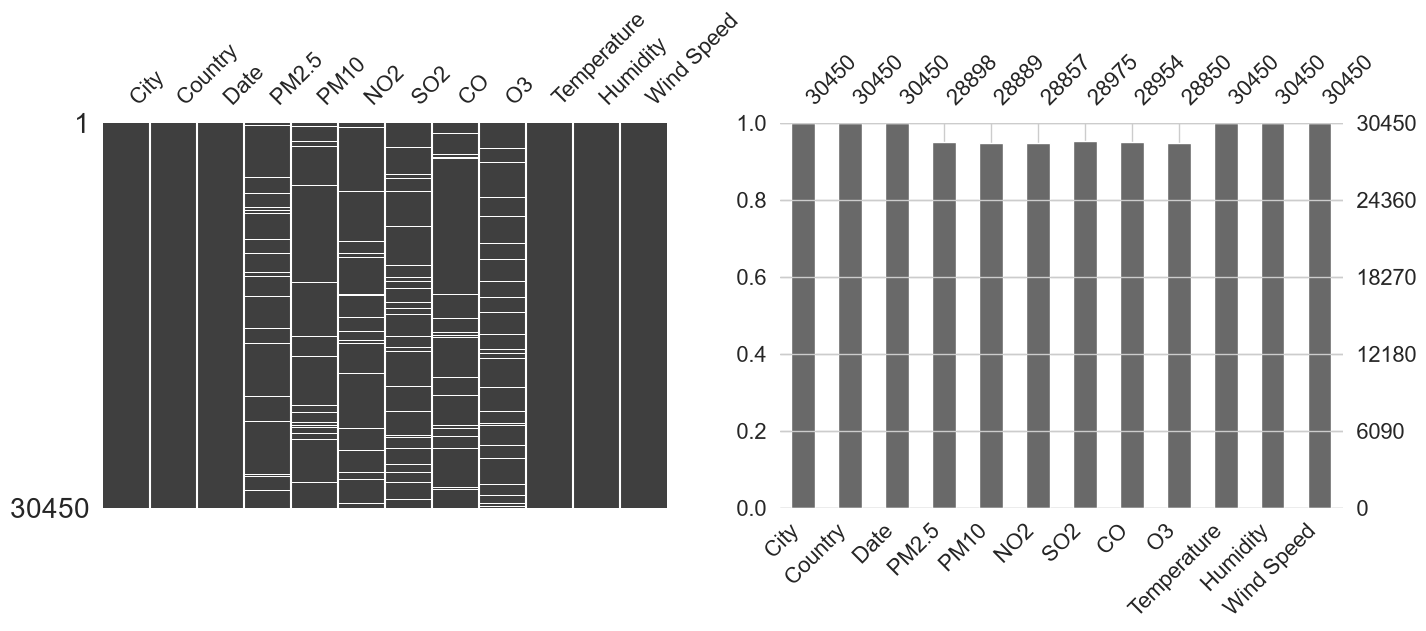

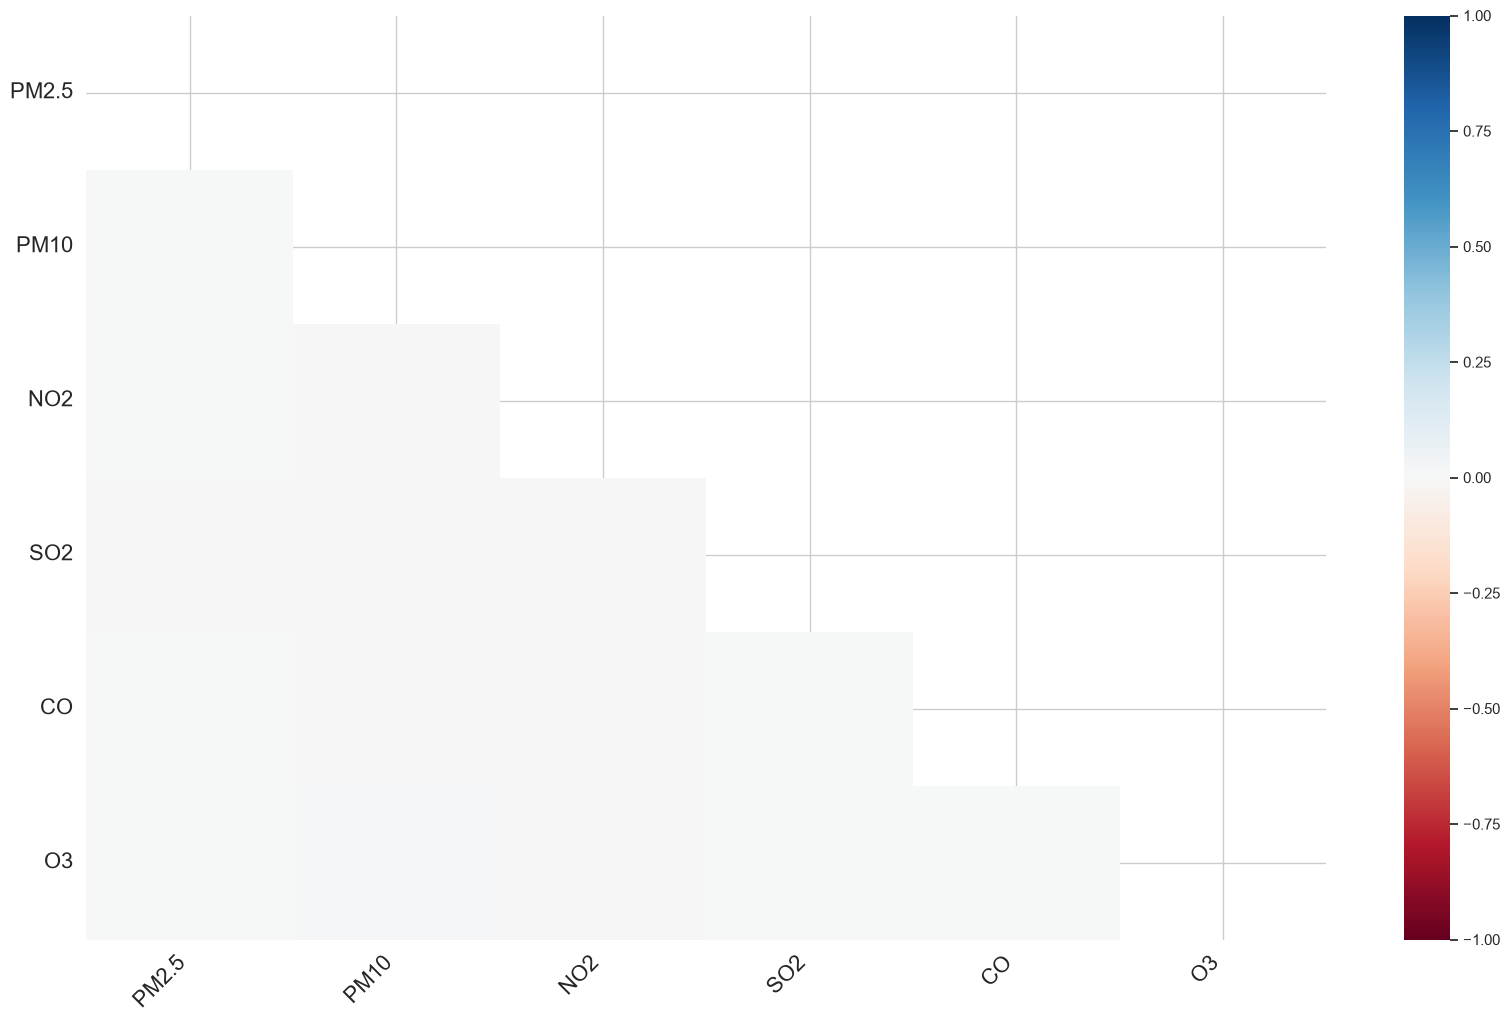

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
msno.matrix(df, ax=axes[0], sparkline=False)
msno.bar(df, ax=axes[1])
plt.show()

msno.heatmap(df)
plt.show()

## Nulos por fila

In [ ]:
nulos_fila = df.isna().sum(axis=1)
print(nulos_fila.value_counts().sort_index())

0    22298
1     7105
2      971
3       74
4        2
Name: count, dtype: int64


## Conclusiones

# Fase II: Análisis exploratorio (EDA)

## Separar tipos de variables

In [16]:
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = df.select_dtypes(["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in num_cols if perfil.loc[c, "categoria"] not in ("constante", "posible identificador")]

## Distribuciones numéricas (histograma + KDE)

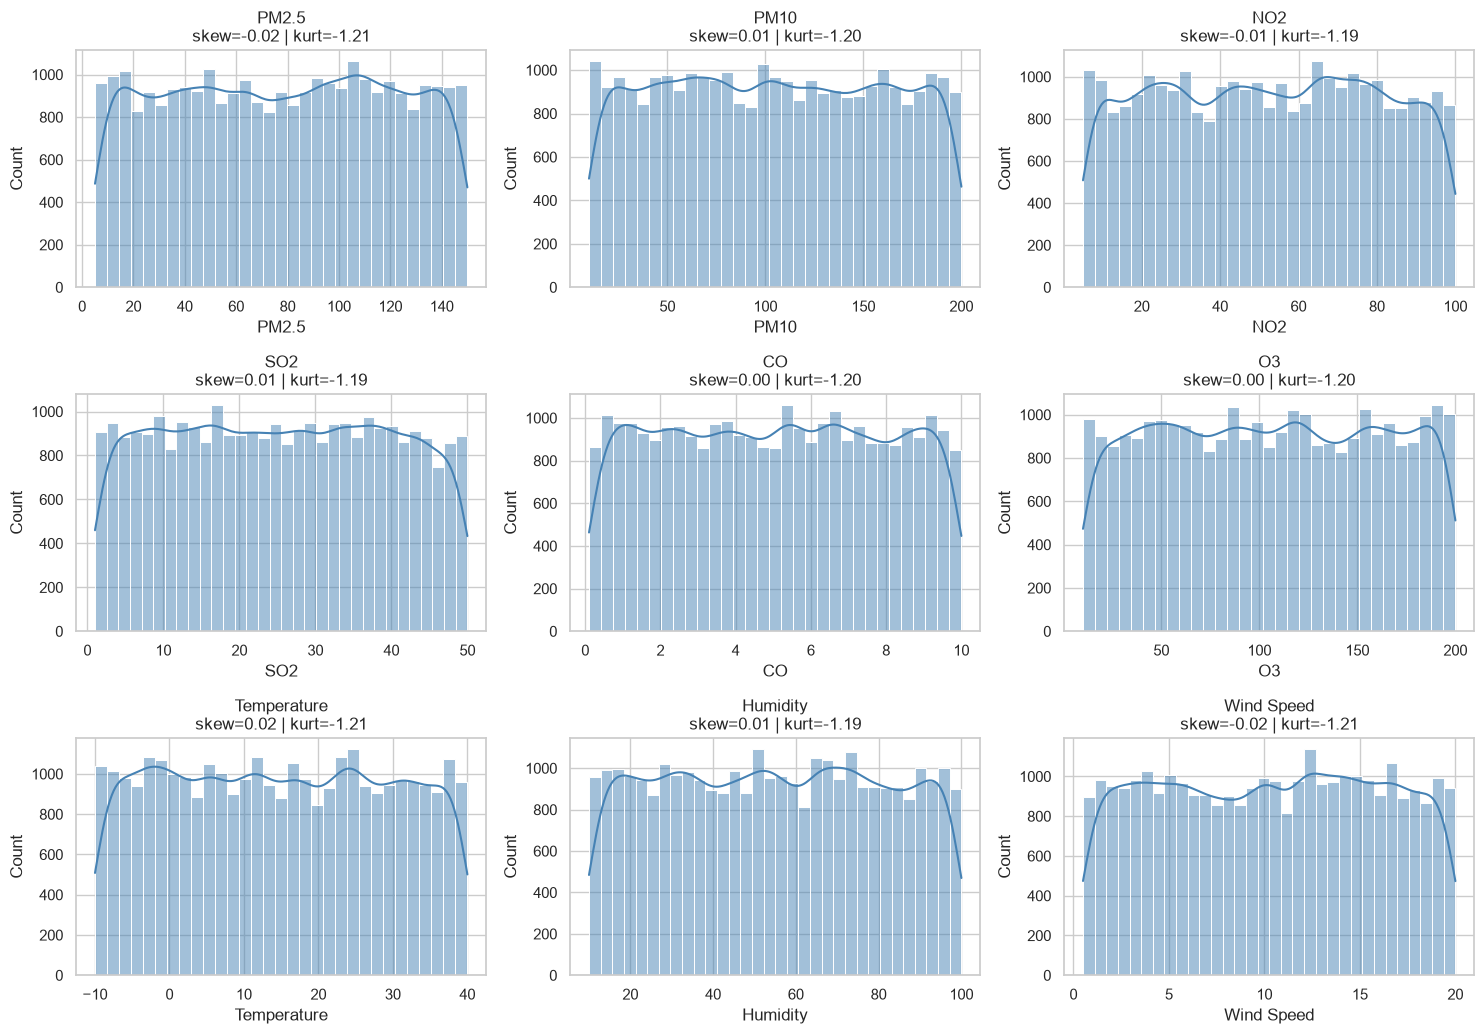

In [17]:
n = len(num_cols); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{c}\nskew={df[c].skew():.2f} | kurt={df[c].kurt():.2f}")
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

## Boxplots para ver colas

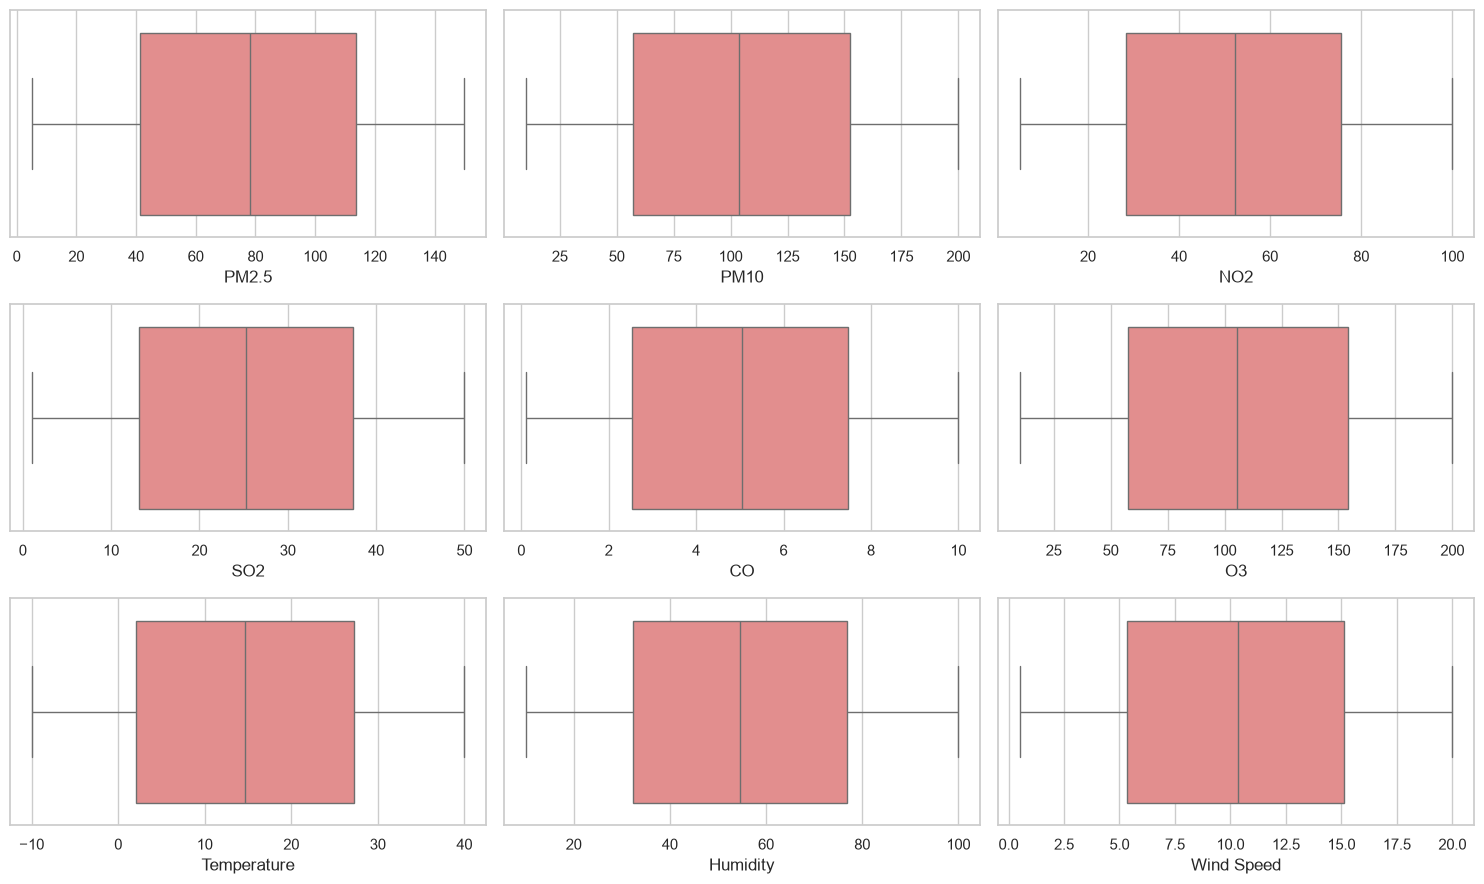

In [18]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
for ax, c in zip(np.array(axes).ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax, color="lightcoral")
plt.tight_layout(); plt.show()

## Test de normalidad

In [19]:
res = []
for c in num_cols:
    x = df[c].dropna()
    stat, p = stats.normaltest(x)          # D'Agostino-Pearson (válido para n grande)
    res.append({"variable": c, "skew": x.skew(), "kurtosis": x.kurt(),
                "p_normalidad": p, "normal (p>0.05)": p > 0.05})
tabla_normalidad = pd.DataFrame(res).set_index("variable")
display(tabla_normalidad.round(4))

,skew,kurtosis,p_normalidad,normal (p>0.05)
variable,,,,
PM2.5,-0.0166,-1.2068,0.0,False
PM10,0.0144,-1.2026,0.0,False
NO2,-0.0083,-1.1891,0.0,False
SO2,0.0101,-1.1898,0.0,False
CO,0.0050,-1.2024,0.0,False
O3,0.0018,-1.2033,0.0,False
Temperature,0.0180,-1.2065,0.0,False
Humidity,0.0057,-1.1942,0.0,False
Wind Speed,-0.0178,-1.2052,0.0,False


## Distribuciones categóricas

City: 120 categorías. Top 10:


City
Mumbai          1394
Toronto         1316
Dubai           1282
Johannesburg    1268
Berlin          1266
Seoul           1265
Cairo           1262
Los Angeles     1256
Bangkok         1243
Sydney          1236
Name: count, dtype: int64

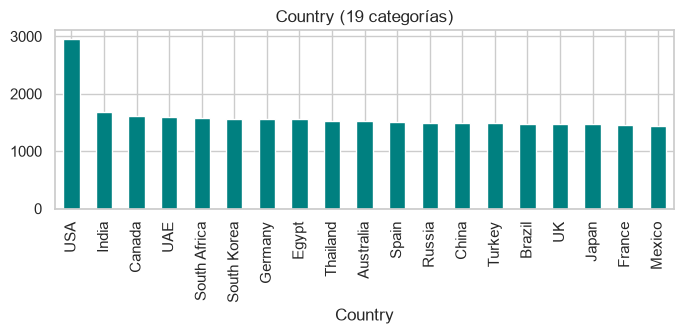

Date: 336 categorías. Top 10:


Date
9/9/2023      168
2/1/2023      159
6/6/2023      143
3/19/2023     143
12/24/2023    141
4/5/2023      139
4/7/2023      139
3/4/2023      136
4/17/2023     135
5/6/2023      132
Name: count, dtype: int64

In [20]:
for c in cat_cols:
    if df[c].nunique() <= 20:
        plt.figure(figsize=(7, 3.5))
        df[c].value_counts(dropna=False).plot.bar(color="teal")
        plt.title(f"{c} ({df[c].nunique()} categorías)"); plt.tight_layout(); plt.show()
    else:
        print(f"{c}: {df[c].nunique()} categorías. Top 10:")
        display(df[c].value_counts().head(10))

## Correlaciones (Pearson vs. Spearman)

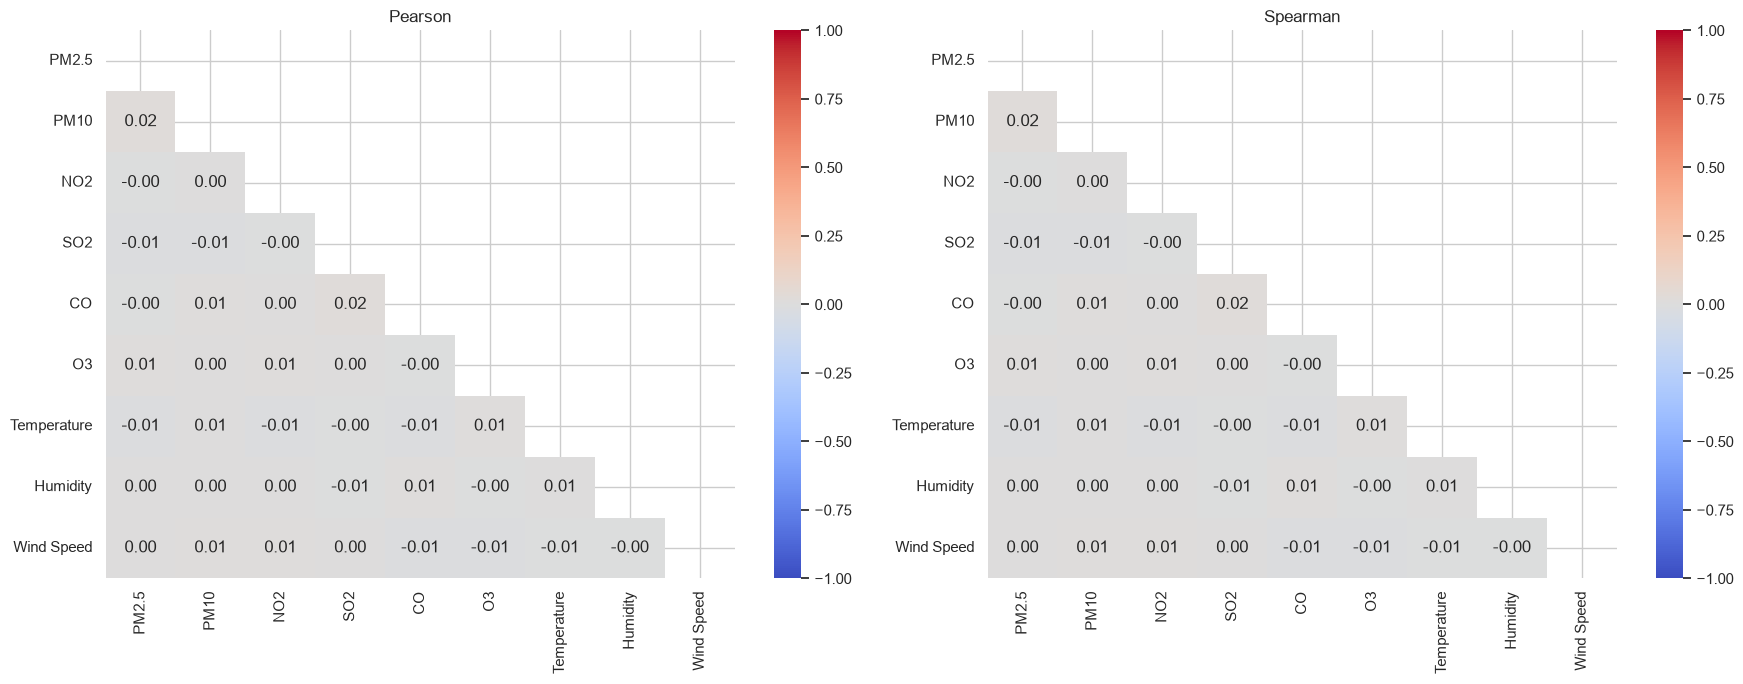

|Spearman - Pearson|
O3       Wind Speed               0.000362
NO2      Humidity                 0.000330
O3       Temperature              0.000274
Humidity Wind Speed               0.000244
NO2      SO2                      0.000228
SO2      Wind Speed               0.000225
         O3                       0.000197
PM10     Temperature              0.000184
         O3                       0.000177
NO2      Wind Speed               0.000161

,level_0,level_1,r


In [21]:
corr_p = df[num_cols].corr(method="pearson")
corr_s = df[num_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
mask = np.triu(np.ones_like(corr_p, dtype=bool))
for ax, m, t in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(t)
plt.tight_layout(); plt.show()

# Pares donde difieren mucho
dif = (corr_s - corr_p).abs()
pares = (dif.where(np.triu(np.ones(dif.shape), k=1).astype(bool))
            .stack().sort_values(ascending=False).head(10))
display(pares.to_frame("|Spearman - Pearson|"))

# Pares más correlacionados
fuertes = (corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool))
                 .stack().rename("r").reset_index())
display(fuertes[fuertes["r"].abs() > 0.7].sort_values("r", key=abs, ascending=False))

## Preguntas analíticas

In [37]:
POLL = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]
METEO = ["Temperature", "Humidity", "Wind Speed"]

eda = df.copy()
eda["Date"] = pd.to_datetime(eda["Date"], format="%d/%m/%Y", errors="coerce")
print("Fechas inválidas:", eda["Date"].isna().sum())
print("Rango:", eda["Date"].min(), "→", eda["Date"].max())

eda["anio"] = eda["Date"].dt.year
eda["mes"] = eda["Date"].dt.month
eda["dia_semana"] = eda["Date"].dt.dayofweek
eda["fin_semana"] = eda["dia_semana"] >= 5

cobertura = eda.groupby(["Country", "City"])["Date"].agg(["count", "min", "max"])
display(cobertura.sort_values("count", ascending=False))

top_ciudades = eda["City"].value_counts().head(8).index

Fechas inválidas: 17283
Rango: 2023-01-01 00:00:00 → 2023-12-12 00:00:00


count        min        max
Country      City                                        
India        Mumbai             594 2023-01-01 2023-12-11
Brazil       Rio de Janeiro     583 2023-01-01 2023-12-12
UAE          Dubai              568 2023-01-02 2023-12-12
USA          Los Angeles        563 2023-01-02 2023-12-11
Egypt        Cairo              555 2023-01-01 2023-12-12
...                             ...        ...        ...
South Africa JOHANNESBURG         1 2023-11-05 2023-11-05
France       PARIS                0        NaT        NaT
             paris                0        NaT        NaT
China        BEIJING              0        NaT        NaT
UAE          dubai                0        NaT        NaT

[120 rows x 3 columns]

### ¿Cómo evoluciona la contaminación en el tiempo?

Hipótesis: hay una tendencia a la baja o al alza según la región, con posibles caídas en periodos específicos (por ejemplo, 2020).

C:\Users\fabio\AppData\Local\Temp\ipykernel_7020\1278727987.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .set_index("Date").groupby("City")["PM2.5"].resample("M").mean().reset_index())


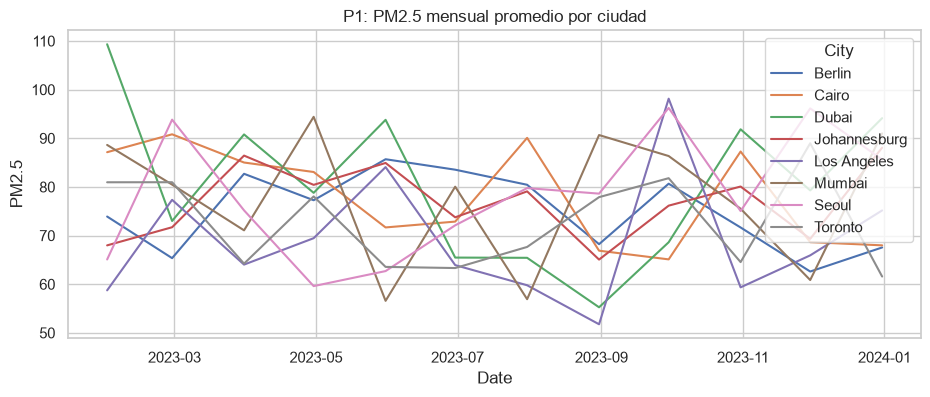

In [ ]:
mensual = (eda[eda["City"].isin(top_ciudades)]
           .set_index("Date").groupby("City")["PM2.5"].resample("M").mean().reset_index())
plt.figure(figsize=(11, 4))
sns.lineplot(data=mensual, x="Date", y="PM2.5", hue="City")
plt.title("PM2.5 mensual promedio por ciudad"); plt.show()

### ¿Existe estacionalidad, y es igual en todas las ciudades?

Hipótesis: el PM2.5 tiene un patrón mensual marcado, pero el mes pico difiere entre ciudades (hemisferio norte vs. sur, zonas tropicales con época seca/lluviosa).

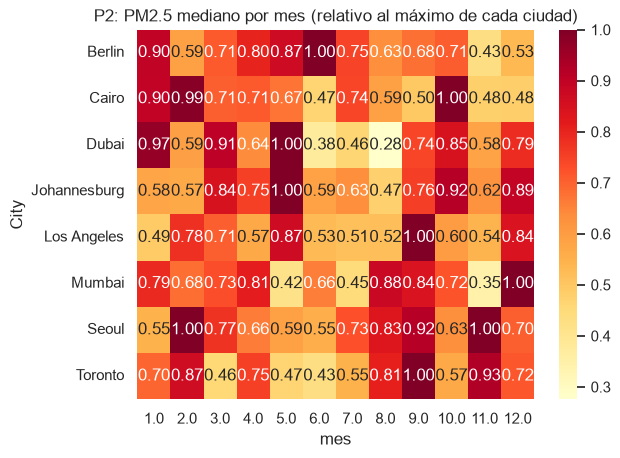

Mumbai: Kruskal-Wallis p = 0.0000
Toronto: Kruskal-Wallis p = 0.0566
Dubai: Kruskal-Wallis p = 0.0000
Johannesburg: Kruskal-Wallis p = 0.3862
Berlin: Kruskal-Wallis p = 0.2979
Seoul: Kruskal-Wallis p = 0.0002
Cairo: Kruskal-Wallis p = 0.0062
Los Angeles: Kruskal-Wallis p = 0.0000


In [ ]:
piv = (eda[eda["City"].isin(top_ciudades)]
       .pivot_table(index="City", columns="mes", values="PM2.5", aggfunc="median"))
# Normalizar por fila para comparar la forma del patrón, no el nivel
sns.heatmap(piv.div(piv.max(axis=1), axis=0), annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Media de PM2.5 por mes (relativo al máximo de cada ciudad)"); plt.show()

for ciudad in top_ciudades:
    g = [x["PM2.5"].dropna() for _, x in eda[eda["City"] == ciudad].groupby("mes")]
    print(f"{ciudad}: Kruskal-Wallis p = {stats.kruskal(*g).pvalue:.4f}")

### ¿Difieren los niveles entre ciudades y países?

Hipótesis: existen diferencias fuertes y significativas entre ciudades; el nivel depende más de la ciudad que de la variación diaria.

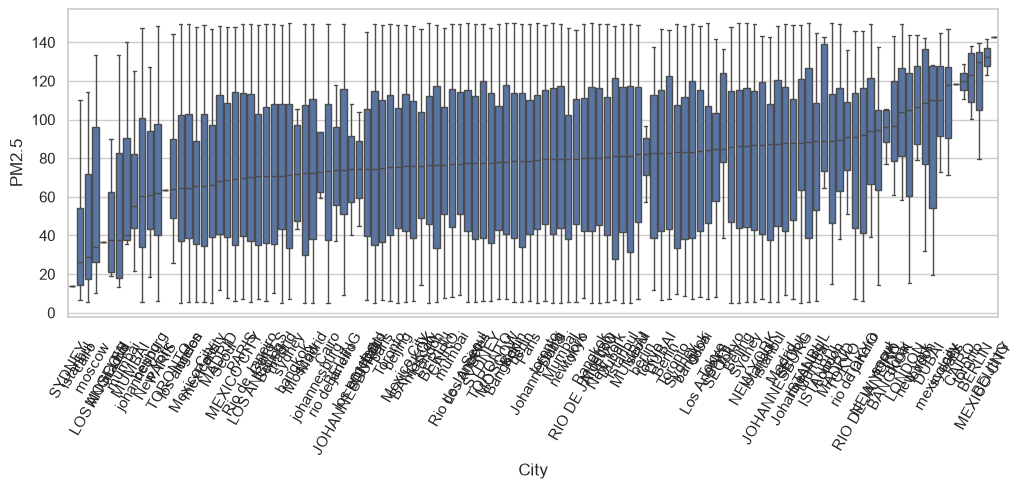

,,count,median,mean,std
Country,City,,,,
Australia,SYDNEY,1,13.71,13.71,NaN
Turkey,istanbul,4,26.24,42.42,46.79
Egypt,cairo,3,28.99,49.71,57.15
Russia,moscow,9,34.16,59.00,45.08
USA,LOS ANGELES,1,36.78,36.78,NaN
...,...,...,...,...,...
Egypt,CAIRO,2,119.81,119.81,12.57
Canada,toronto,4,122.98,121.08,17.72
Germany,BERLIN,3,130.04,116.48,32.31


Kruskal-Wallis p = 0.0050817316708282444


In [40]:
orden = eda.groupby("City")["PM2.5"].median().sort_values().index
plt.figure(figsize=(12, 4))
sns.boxplot(data=eda[eda["City"].isin(orden)], x="City", y="PM2.5", order=orden, showfliers=False)
plt.xticks(rotation=60); plt.show()

display(eda.groupby(["Country", "City"])["PM2.5"]
           .agg(["count", "median", "mean", "std"]).round(2).sort_values("median"))

grupos = [g["PM2.5"].dropna() for _, g in eda.groupby("City")]
print("Kruskal-Wallis p =", stats.kruskal(*grupos).pvalue)

### ¿Cómo influyen las variables meteorológicas?

Hipótesis: el viento fuerte dispersa contaminantes (correlación negativa); la temperatura se asocia positivamente con O3; la humedad alta favorece PM2.5.

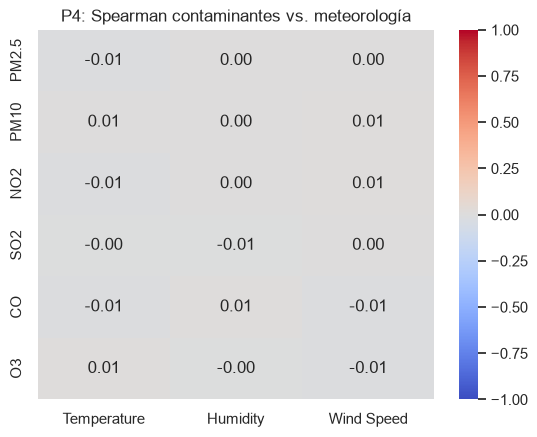

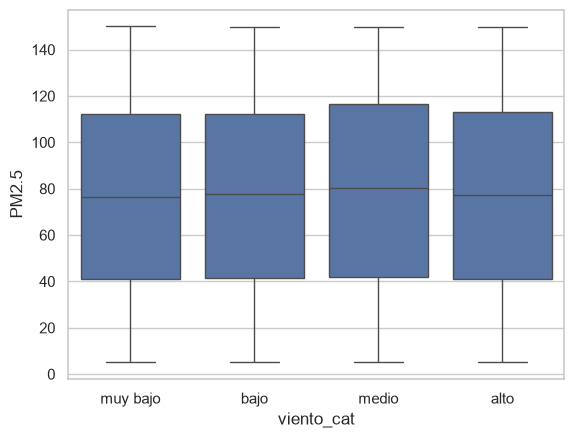

In [ ]:
corr = eda[POLL + METEO].corr(method="spearman").loc[POLL, METEO]
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman contaminantes vs. meteorología"); plt.show()

eda["viento_cat"] = pd.qcut(eda["Wind Speed"], 4, labels=["muy bajo", "bajo", "medio", "alto"])
sns.boxplot(data=eda, x="viento_cat", y="PM2.5", showfliers=False); plt.show()

### ¿Qué contaminantes se mueven juntos?

Hipótesis: PM2.5 y PM10 tienen correlación muy alta (r > 0.8); O3 se relaciona negativamente con NO2; CO y NO2 comparten fuente (tráfico).

In [ ]:
p, s = eda[POLL].corr("pearson"), eda[POLL].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, m, t in zip(axes, [p, s], ["Pearson", "Spearman"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title(t)
plt.show()

sns.scatterplot(data=eda.sample(min(5000, len(eda)), random_state=RANDOM_STATE),
                x="PM10", y="PM2.5", alpha=.3)

### ¿Con qué frecuencia se superan los umbrales de la OMS?

Guías OMS 2021 para 24 h: PM2.5 = 15, PM10 = 45, NO2 = 25 µg/m³. Como tus datos ya son diarios, se comparan directamente (verifica que sus unidades sean µg/m³).

In [42]:
umbrales = {"PM2.5": 15, "PM10": 45, "NO2": 25}
exced = pd.DataFrame({c: (eda[c].dropna() > u).groupby(eda["City"]).mean() * 100
                      for c, u in umbrales.items()}).round(1)
display(exced.rename(columns=lambda c: f"% días > OMS ({c})").sort_values(
    "% días > OMS (PM2.5)", ascending=False))

,% días > OMS (PM2.5),% días > OMS (PM10),% días > OMS (NO2)
City,,,
BANGKOK,100.0,100.0,100.0
BEIJING,100.0,NaN,100.0
BERLIN,100.0,33.3,66.7
CAIRO,100.0,100.0,50.0
DUBAI,100.0,83.3,100.0
...,...,...,...
moscow,77.8,70.0,77.8
istanbul,75.0,100.0,66.7
tokyo,71.4,100.0,50.0


### ¿Cambia el patrón entre días laborales y fines de semana?

Hipótesis: menos tráfico el fin de semana implica menos NO2 y CO.

In [43]:
for c in ["NO2", "CO", "PM2.5"]:
    a = eda.loc[eda["fin_semana"], c].dropna()
    b = eda.loc[~eda["fin_semana"], c].dropna()
    print(f"{c}: laboral={b.median():.2f} | fin de semana={a.median():.2f} "
          f"| Mann-Whitney p={stats.mannwhitneyu(a, b).pvalue:.4f}")

NO2: laboral=52.23 | fin de semana=52.88 | Mann-Whitney p=0.2294
CO: laboral=5.04 | fin de semana=5.36 | Mann-Whitney p=0.0133
PM2.5: laboral=77.69 | fin de semana=80.58 | Mann-Whitney p=0.4365


### Preguntas de calidad del dato

#### 1. Valores centinela o imposibles

In [60]:
print((eda[POLL] < 0).sum())
print((eda[POLL] == 0).sum())
print(eda[POLL + METEO].describe().loc[["min", "max"]])

PM2.5    0
PM10     0
NO2      0
SO2      0
CO       0
O3       0
dtype: int64
PM2.5    0
PM10     0
NO2      0
SO2      0
CO       0
O3       0
dtype: int64
      PM2.5   PM10     NO2    SO2    CO      O3  Temperature  Humidity  \
min    5.02   10.0    5.01   1.00   0.1   10.04        -10.0     10.01   
max  149.98  200.0  100.00  49.99  10.0  200.00         40.0     99.99   

     Wind Speed  
min         0.5  
max        20.0  


#### 2. ¿Nulos concentrados en ciudades?

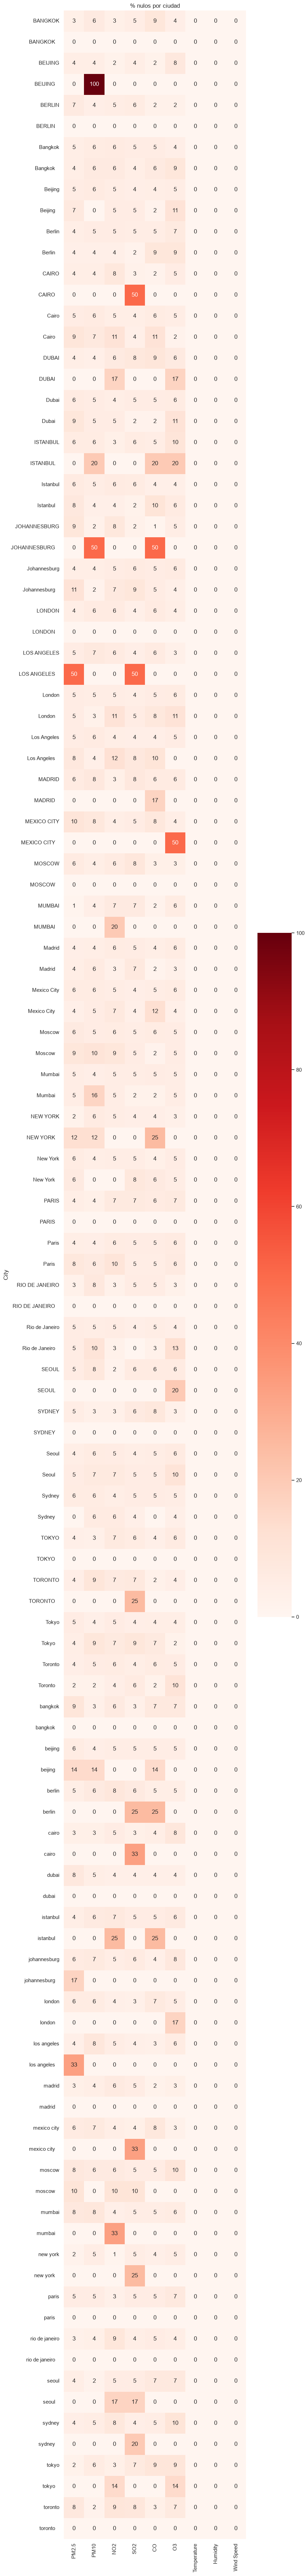

In [61]:
nulos = eda.groupby("City")[POLL + METEO].apply(lambda x: x.isna().mean() * 100).round(1)

plt.figure(figsize=(1.0 * len(nulos.columns), 0.6 * len(nulos) + 2))
sns.heatmap(nulos, annot=True, cmap="Reds", fmt=".0f")
plt.title("% nulos por ciudad")
plt.tight_layout()
plt.show()

#### 3. Duplicados parciales: misma ciudad y fecha repetida

In [46]:
print("Duplicados City+Date:", eda.duplicated(subset=["City", "Date"]).sum())

Duplicados City+Date: 26203


#### 4. Consistencia City-Country (una ciudad asignada a dos países, o variantes de escritura)

In [62]:
print(eda.groupby("City")["Country"].nunique().loc[lambda s: s > 1])
print(sorted(eda["City"].dropna().unique())[:50])

Series([], Name: Country, dtype: int64)
['BANGKOK', 'BANGKOK   ', 'BEIJING', 'BEIJING   ', 'BERLIN', 'BERLIN   ', 'Bangkok', 'Bangkok   ', 'Beijing', 'Beijing   ', 'Berlin', 'Berlin   ', 'CAIRO', 'CAIRO   ', 'Cairo', 'Cairo   ', 'DUBAI', 'DUBAI   ', 'Dubai', 'Dubai   ', 'ISTANBUL', 'ISTANBUL   ', 'Istanbul', 'Istanbul   ', 'JOHANNESBURG', 'JOHANNESBURG   ', 'Johannesburg', 'Johannesburg   ', 'LONDON', 'LONDON   ', 'LOS ANGELES', 'LOS ANGELES   ', 'London', 'London   ', 'Los Angeles', 'Los Angeles   ', 'MADRID', 'MADRID   ', 'MEXICO CITY', 'MEXICO CITY   ', 'MOSCOW', 'MOSCOW   ', 'MUMBAI', 'MUMBAI   ', 'Madrid', 'Madrid   ', 'Mexico City', 'Mexico City   ', 'Moscow', 'Moscow   ']


# Fase III: Limpieza de datos

In [63]:
df_clean = df_raw.copy(deep=True)
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

### Valores nulos

In [64]:
def diagnostico_mar(data, col_nula, cols_num):
    """Compara otras variables entre filas con y sin nulo en col_nula."""
    ind = data[col_nula].isna()
    filas = []
    for c in cols_num:
        if c == col_nula: continue
        a, b = data.loc[ind, c].dropna(), data.loc[~ind, c].dropna()
        if len(a) > 5 and len(b) > 5:
            filas.append({"variable": c,
                          "media_con_nulo": a.mean(), "media_sin_nulo": b.mean(),
                          "p_valor": stats.mannwhitneyu(a, b).pvalue})
    return pd.DataFrame(filas).sort_values("p_valor")

cols_con_nulos = df_clean.columns[df_clean.isna().any()]
for c in cols_con_nulos:
    if c in num_cols:
        print(f"\n--- Nulos en '{c}' ({df_clean[c].isna().mean():.1%}) ---")
        display(diagnostico_mar(df_clean, c, num_cols).head(5))


--- Nulos en 'PM2.5' (5.1%) ---


,variable,media_con_nulo,media_sin_nulo,p_valor
6,Humidity,53.644343,54.851129,0.074792
3,CO,5.139137,5.023166,0.128646
4,O3,103.984908,105.628749,0.266118
1,NO2,51.560197,52.275119,0.321882
7,Wind Speed,10.327513,10.269653,0.687607



--- Nulos en 'PM10' (5.1%) ---


,variable,media_con_nulo,media_sin_nulo,p_valor
4,O3,100.729365,105.802909,0.000616
6,Humidity,53.867694,54.839436,0.150377
3,CO,5.102186,5.025098,0.312629
5,Temperature,14.455554,14.820034,0.328680
0,PM2.5,77.164109,77.677124,0.642406



--- Nulos en 'NO2' (5.2%) ---


,variable,media_con_nulo,media_sin_nulo,p_valor
0,PM2.5,80.425106,77.498082,0.008250
5,Temperature,15.133283,14.783026,0.342539
1,PM10,105.449484,104.313886,0.434904
7,Wind Speed,10.350672,10.268292,0.555112
3,CO,5.063933,5.027121,0.627102


... (2 outputs left out)


--- Nulos en 'CO' (4.9%) ---


,variable,media_con_nulo,media_sin_nulo,p_valor
7,Wind Speed,10.559158,10.257796,0.043017
3,SO2,24.569200,25.320704,0.051469
5,Temperature,15.259572,14.777674,0.209379
2,NO2,51.456480,52.279390,0.263164
1,PM10,103.214782,104.433301,0.410238



--- Nulos en 'O3' (5.3%) ---


,variable,media_con_nulo,media_sin_nulo,p_valor
5,Temperature,15.518656,14.761568,0.041651
2,NO2,51.184492,52.297547,0.115261
6,Humidity,53.950412,54.836162,0.185953
1,PM10,102.685379,104.466024,0.222789
7,Wind Speed,10.132638,10.280364,0.294336


### Aplicar la estrategia por columna

,pct_nulos,sugerencia,motivo
columna,,,
PM2.5,5.01,media_ciudad,skew=0.01 (≈ simétrica)
PM10,5.29,media_ciudad,skew=0.00 (≈ simétrica)
NO2,5.03,media_ciudad,skew=-0.03 (≈ simétrica)
SO2,4.94,interpolacion,"4.9% nulos, serie diaria por ciudad"
CO,4.75,interpolacion,"4.7% nulos, serie diaria por ciudad"
O3,5.14,media_ciudad,skew=-0.00 (≈ simétrica)


Hueco consecutivo más largo por ciudad (días):


,PM2.5,PM10,NO2,SO2,CO,O3
City,,,,,,
BANGKOK,1,1,1,1,2,1
BANGKOK,0,0,0,0,0,0
BEIJING,1,1,1,1,0,1
BERLIN,1,0,1,1,0,1
BERLIN,0,0,0,0,0,0
...,...,...,...,...,...,...
sydney,0,0,0,1,0,0
tokyo,1,1,2,1,2,1
tokyo,0,0,0,0,0,0


PM2.5: media 77.65→76.79 | std 42.01→41.27 | KS p=0.000 (REVISAR)


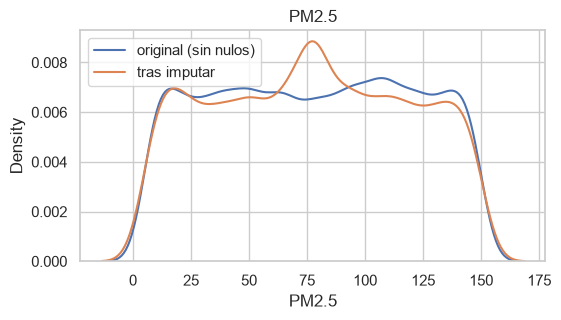

PM10: media 104.37→105.38 | std 55.06→54.13 | KS p=0.000 (REVISAR)


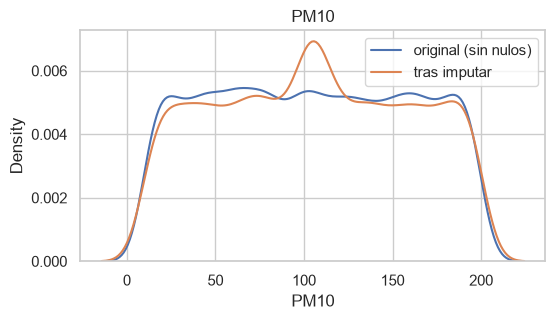

NO2: media 52.24→52.43 | std 27.33→26.83 | KS p=0.000 (REVISAR)


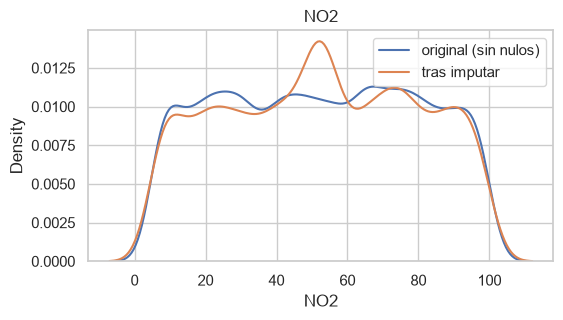

SO2: media 25.28→25.19 | std 14.06→13.79 | KS p=0.027 (REVISAR)


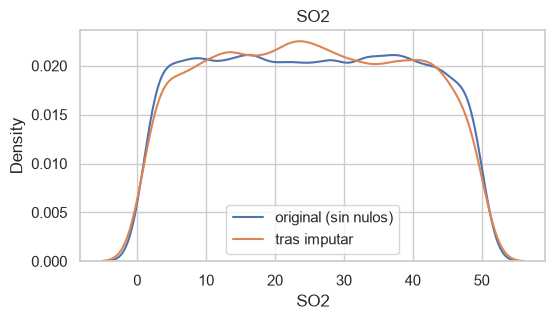

CO: media 5.03→5.11 | std 2.86→2.82 | KS p=0.001 (REVISAR)


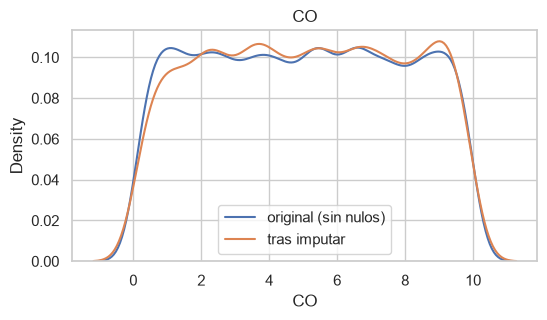

O3: media 105.55→105.36 | std 55.15→54.04 | KS p=0.000 (REVISAR)


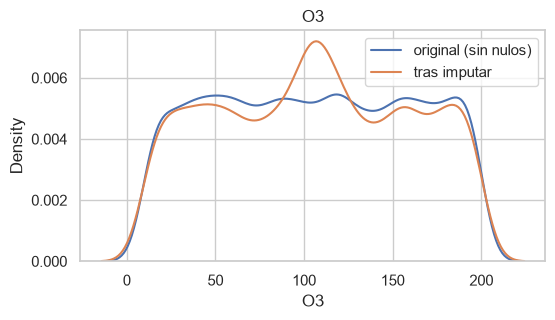

Nulos restantes: 0


,fase,columna,accion,justificacion
0,III-nulos,Date,Eliminar 17283 filas,Clave de agrupación/tiempo: no se puede imputa...
1,III-nulos,PM2.5,media_ciudad (660 valores),skew=0.01 (≈ simétrica)
2,III-nulos,PM10,media_ciudad (697 valores),skew=0.00 (≈ simétrica)
3,III-nulos,NO2,media_ciudad (662 valores),skew=-0.03 (≈ simétrica)
4,III-nulos,SO2,interpolacion (650 valores),"4.9% nulos, serie diaria por ciudad"
5,III-nulos,CO,interpolacion (625 valores),"4.7% nulos, serie diaria por ciudad"
6,III-nulos,O3,media_ciudad (677 valores),skew=-0.00 (≈ simétrica)


In [68]:
NUM = POLL + METEO
CLAVES = ["City", "Country", "Date"]

# Claves (City, Country, Date): no se imputan, se eliminan las filas afectadas
for c in CLAVES:
    n = df_clean[c].isna().sum()
    if n > 0:
        df_clean = df_clean.dropna(subset=[c])
        registrar("III-nulos", c, f"Eliminar {n} filas",
                  "Clave de agrupación/tiempo: no se puede imputar con fiabilidad")

df_clean = df_clean.sort_values(["City", "Date"]).reset_index(drop=True)

# ---------- 2. Funciones de diagnóstico ----------
def diagnostico_mar(data, col_nula, cols_num):
    """Compara otras variables entre filas con y sin nulo (indicio de MAR)."""
    ind = data[col_nula].isna()
    filas = []
    for c in cols_num:
        if c == col_nula or c not in data: continue
        a, b = data.loc[ind, c].dropna(), data.loc[~ind, c].dropna()
        if len(a) > 5 and len(b) > 5:
            filas.append({"variable": c, "media_con_nulo": a.mean(),
                          "media_sin_nulo": b.mean(),
                          "p_valor": stats.mannwhitneyu(a, b).pvalue})
    return pd.DataFrame(filas, columns=["variable", "media_con_nulo",
                                        "media_sin_nulo", "p_valor"])

def max_hueco(s):
    """Longitud del hueco consecutivo de nulos más largo."""
    g = s.isna().ne(s.isna().shift()).cumsum()
    return s.isna().groupby(g).sum().max()

def sugerir_imputacion(df, c, cols_num):
    s = df[c]
    pct = s.isna().mean() * 100
    if pct > 60:
        return "eliminar_columna", f"{pct:.0f}% nulos"
    mar = diagnostico_mar(df, c, cols_num)
    n_sig = (mar["p_valor"] < 0.05).sum() if len(mar) else 0
    otras = [x for x in cols_num if x != c and x in df]
    r_max = df[otras + [c]].corr("spearman")[c].drop(c).abs().max()
    if r_max > 0.5 and n_sig >= 2:
        return "iterativa", f"MAR probable ({n_sig} vars sig.), r_max={r_max:.2f}"
    if pct < 5:
        return "interpolacion", f"{pct:.1f}% nulos, serie diaria por ciudad"
    if abs(s.skew()) > 1:
        return "mediana_ciudad", f"skew={s.skew():.2f} (sesgada)"
    return "media_ciudad", f"skew={s.skew():.2f} (≈ simétrica)"

# ---------- 3. Tabla de sugerencias (propuesta automática) ----------
num_nulas = [c for c in NUM if c in df_clean and df_clean[c].isna().any()]
plan = pd.DataFrame(
    [{"columna": c,
      "pct_nulos": round(df_clean[c].isna().mean() * 100, 2),
      "sugerencia": sugerir_imputacion(df_clean, c, NUM)[0],
      "motivo": sugerir_imputacion(df_clean, c, NUM)[1]} for c in num_nulas]
).set_index("columna")
display(plan)

huecos = df_clean.groupby("City")[num_nulas].agg(max_hueco)
print("Hueco consecutivo más largo por ciudad (días):")
display(huecos)

# ---------- 4. REVISIÓN MANUAL: ajusta aquí según plan y huecos ----------
estrategias = plan["sugerencia"].to_dict()
# Ejemplos (descomenta y justifica en tu notebook si cambias algo):
# estrategias["Humidity"] = "interpolacion"
# estrategias["CO"] = "mediana_ciudad"

# ---------- 5. Funciones de imputación univariada (por ciudad) ----------
def imp_media_ciudad(df, c):
    df[c] = df[c].fillna(df.groupby("City")[c].transform("mean"))
    df[c] = df[c].fillna(df[c].mean())                         # respaldo global

def imp_mediana_ciudad(df, c):
    df[c] = df[c].fillna(df.groupby("City")[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())

def imp_interpolacion(df, c, limite=3):
    df[c] = df.groupby("City")[c].transform(
        lambda s: s.interpolate(limit=limite, limit_direction="both"))
    df[c] = df[c].fillna(df.groupby("City")[c].transform("median"))  # huecos largos
    df[c] = df[c].fillna(df[c].median())

funciones = {"media_ciudad": imp_media_ciudad,
             "mediana_ciudad": imp_mediana_ciudad,
             "interpolacion": imp_interpolacion}

# ---------- 6. Aplicación ----------
# 6.1 Eliminar columnas (afecta a todo lo demás)
for c, est in list(estrategias.items()):
    if est == "eliminar_columna":
        df_clean = df_clean.drop(columns=c)
        registrar("III-nulos", c, "Eliminar columna", plan.loc[c, "motivo"])
        estrategias.pop(c)

# 6.2 Imputaciones univariadas
for c, est in estrategias.items():
    if est in funciones and c in df_clean:
        n = df_clean[c].isna().sum()
        funciones[est](df_clean, c)
        registrar("III-nulos", c, f"{est} ({n} valores)", plan.loc[c, "motivo"])

# 6.3 Imputación multivariada: una sola vez para todo el grupo
cols_iter = [c for c, e in estrategias.items() if e == "iterativa" and c in df_clean]
if cols_iter:
    predictores = [c for c in dict.fromkeys(cols_iter + METEO) if c in df_clean]
    imp = IterativeImputer(estimator=BayesianRidge(), max_iter=10,
                           random_state=RANDOM_STATE)
    df_clean[predictores] = imp.fit_transform(df_clean[predictores])
    for c in cols_iter:
        registrar("III-nulos", c, "Imputación iterativa (BayesianRidge)",
                  plan.loc[c, "motivo"])

# ---------- 7. Validación de la imputación ----------
def validar_imputacion(original, imputada, nombre):
    o, i = original.dropna(), imputada.dropna()
    ks = stats.ks_2samp(o, i)
    print(f"{nombre}: media {o.mean():.2f}→{i.mean():.2f} | std {o.std():.2f}→{i.std():.2f} "
          f"| KS p={ks.pvalue:.3f} ({'OK' if ks.pvalue > 0.05 else 'REVISAR'})")
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.kdeplot(o, label="original (sin nulos)", ax=ax)
    sns.kdeplot(i, label="tras imputar", ax=ax)
    ax.legend(); ax.set_title(nombre); plt.show()

for c in num_nulas:
    if c in df_clean:
        validar_imputacion(df_raw[c], df_clean[c], c)

print("Nulos restantes:", df_clean.isna().sum().sum())
display(pd.DataFrame(decisiones).query("fase == 'III-nulos'"))

### Outliers

In [69]:
def out_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def out_z(s, umbral=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > umbral

def out_mad(s, umbral=3.5):
    """Z-score modificado (robusto): usa mediana y MAD."""
    med = s.median(); mad = stats.median_abs_deviation(s.dropna())
    if mad == 0: return pd.Series(False, index=s.index)
    return (0.6745 * (s - med) / mad).abs() > umbral

resumen_out = pd.DataFrame({
    c: {"IQR": out_iqr(df_clean[c]).sum(),
        "Z-score": out_z(df_clean[c]).sum(),
        "MAD": out_mad(df_clean[c]).sum(),
        "% IQR": round(out_iqr(df_clean[c]).mean() * 100, 2)}
    for c in num_cols
}).T
display(resumen_out)

,IQR,Z-score,MAD,% IQR
PM2.5,0.0,0.0,0.0,0.0
PM10,0.0,0.0,0.0,0.0
NO2,0.0,0.0,0.0,0.0
SO2,0.0,0.0,0.0,0.0
CO,0.0,0.0,0.0,0.0
O3,0.0,0.0,0.0,0.0
Temperature,0.0,0.0,0.0,0.0
Humidity,0.0,0.0,0.0,0.0
Wind Speed,0.0,0.0,0.0,0.0


In [70]:
from sklearn.covariance import MinCovDet

cols_mv = num_cols[:5]                                # elige variables relevantes
datos = df_clean[cols_mv].dropna()
mcd = MinCovDet(random_state=RANDOM_STATE).fit(datos)
d2 = mcd.mahalanobis(datos)                           # distancia² robusta
corte = stats.chi2.ppf(0.999, df=len(cols_mv))        # umbral chi-cuadrado
out_mv = pd.Series(d2 > corte, index=datos.index)
print(f"Outliers multivariados: {out_mv.sum()} ({out_mv.mean():.2%})")

Outliers multivariados: 0 (0.00%)
